# Calibración

## Checkerboard usado

| Parámetro | Valor |
|---|---|
| Esquinas internas (columnas × filas) | 9 × 6 (54 puntos) |
| Cantidad de cuadrados (columnas × filas) | 10 × 7 |
| Lado de cada cuadrado | 28 mm (2,8 cm) |
| Tamaño del patrón, sin márgenes | 280 × 196 mm |

In [5]:
import sys
from pathlib import Path

ROOT_DIR = Path.cwd().parent
sys.path.append(str(ROOT_DIR))

## Imports de módulos

In [6]:
import pickle
import cv2 as cv
import numpy as np
import matplotlib.pyplot as plt
import glob
import os

from src.utils.prints import print_matrix

## Carga de datos

Contenidos de stereo_calibration.pkl

| Clave | Tipo / forma | Qué contiene |
|---|---|---|
| `left_K` | array `(3, 3)` | Matriz de parámetros intrínsecos de la cámara izquierda |
| `right_K` | array `(3, 3)` | Matriz de parámetros intrínsecos de la cámara derecha |
| `left_dist` | array `(1, 5)` | Coeficientes de distorsión de la izquierda |
| `right_dist` | array `(1, 5)` | Coeficientes de distorsión de la derecha |
| `R` | array `(3, 3)` | Rotación entre las cámaras |
| `T` | array `(3, 1)` | Traslación entre las cámaras |
| `E` | array `(3, 3)` | Matriz esencial |
| `F` | array `(3, 3)` | Matriz fundamental |
| `image_size` | tupla `(1920, 1080)` | Tamaño de imagen: `(ancho, alto)` |

---

Contenidos de stereo_maps.pkl

| Clave | Tipo / forma | Qué contiene |
|---|---|---|
| `left_map_x` | array `(1080, 1920)`, `float32` | Coordenadas X de origen para rectificar la imagen izquierda |
| `left_map_y` | array `(1080, 1920)`, `float32` | Coordenadas Y de origen para rectificar la imagen izquierda |
| `right_map_x` | array `(1080, 1920)`, `float32` | Coordenadas X de origen para rectificar la imagen derecha |
| `right_map_y` | array `(1080, 1920)`, `float32` | Coordenadas Y de origen para rectificar la imagen derecha |
| `R1` | array `(3, 3)`, `float64` | Rotación de rectificación izquierda |
| `R2` | array `(3, 3)`, `float64` | Rotación de rectificación derecha |
| `P1` | array `(3, 4)`, `float64` | Matriz de proyección izquierda rectificada |
| `P2` | array `(3, 4)`, `float64` | Matriz de proyección derecha rectificada |
| `Q` | array `(4, 4)`, `float64` | Matriz para convertir disparidad en coordenadas 3D |
| `validRoi1` | tupla `(0, 1, 1920, 1079)` | Región válida izquierda: `(x, y, ancho, alto)` |
| `validRoi2` | tupla `(0, 0, 1920, 1080)` | Región válida derecha: `(x, y, ancho, alto)` |

In [7]:
CALIBRATION_DIR = ROOT_DIR / "data/calibration_results"

with (CALIBRATION_DIR / "stereo_calibration.pkl").open("rb") as f:
    calib: dict = pickle.load(f)

with (CALIBRATION_DIR / "stereo_maps.pkl").open("rb") as f:
    maps: dict = pickle.load(f)

## 1. Parámetros de calibración

In [8]:
for k, v in calib.items():
    if k == "image_size":
        print(f"{k} = {v}")
        continue
    print_matrix(name=k, matrix=v)

print(f"baseline = {np.linalg.norm(calib.get('T'))}")

K1, D1 = calib['left_K'], calib['left_dist']
K2, D2 = calib['right_K'], calib['right_dist']
R, t = calib['R'], calib['T']

image_size = calib['image_size']

587.482,0,990.671
0,593.957,552.905
0,0,1


-0.026457,0.00706564,0.00214563,0.00358874,-0.00371444


602.448,0,931.245
0,597.977,516.344
0,0,1


0.0114667,-0.0386206,-0.000216791,-0.0127469,0.00601503


0.997875,0.00114852,0.0651462
-0.00357237,0.999305,0.037102
-0.0650583,-0.0372559,0.997186


-56.8894
1.85426
9.35663


-0.08721,-9.41921,1.5019
5.63561,-2.10872,57.3389
-1.64709,-56.852,-2.23151


4.37342e-08,4.67206e-06,-0.00306901
-2.84729e-06,1.05378e-06,-0.0147809
0.00192707,0.0120937,1


image_size = (1920, 1080)
baseline = 57.683564136797926


## 2. Error de reproyección

In [9]:
# --- Validación del error de reproyección de la calibración guardada ---
columnas = 9
filas = 6
tamanio_cuadrado_mm = 28.0

# Puntos 3D teóricos del tablero (en mm)
objp = np.zeros((filas * columnas, 3), np.float32)
objp[:, :2] = np.mgrid[0:columnas, 0:filas].T.reshape(-1, 2) * tamanio_cuadrado_mm

criteria = (cv.TERM_CRITERIA_EPS + cv.TERM_CRITERIA_MAX_ITER, 30, 0.001)

images_left = sorted(glob.glob('../data/calibration/left_*.jpg'))
images_right = sorted(glob.glob('../data/calibration/right_*.jpg'))

objpoints, imgpoints_left, imgpoints_right = [], [], []
for img_left_path, img_right_path in zip(images_left, images_right):
    imgL = cv.imread(img_left_path, cv.IMREAD_GRAYSCALE)
    imgR = cv.imread(img_right_path, cv.IMREAD_GRAYSCALE)
    retL, cornersL = cv.findChessboardCorners(imgL, (columnas, filas), None)
    retR, cornersR = cv.findChessboardCorners(imgR, (columnas, filas), None)
    if retL and retR:
        objpoints.append(objp)
        imgpoints_left.append(cv.cornerSubPix(imgL, cornersL, (11, 11), (-1, -1), criteria))
        imgpoints_right.append(cv.cornerSubPix(imgR, cornersR, (11, 11), (-1, -1), criteria))

print(f"Pares con tablero detectado: {len(objpoints)} / {len(images_left)}")

# 1) RMS monocular de cada cámara: mide la calidad de los intrínsecos guardados
rms_L, *_ = cv.calibrateCamera(objpoints, imgpoints_left, image_size, None, None)
rms_R, *_ = cv.calibrateCamera(objpoints, imgpoints_right, image_size, None, None)
print(f"RMS monocular   izquierda = {rms_L:.3f} px | derecha = {rms_R:.3f} px")

# 2) RMS de reproyección estéreo de la calibración GUARDADA (K1,D1,K2,D2,R,t del .pkl).
#    Para cada par: pose del tablero con la izquierda (solvePnP), se transforma con
#    (R,t) al sistema de la derecha y se reproyecta. Se compara con las esquinas detectadas.
sq_err, n_pts, baselines = 0.0, 0, []
for objp_i, pL, pR in zip(objpoints, imgpoints_left, imgpoints_right):
    _, rvec, tvec = cv.solvePnP(objp_i, pL, K1, D1)
    projL, _ = cv.projectPoints(objp_i, rvec, tvec, K1, D1)
    R_board, _ = cv.Rodrigues(rvec)
    rvecR, _ = cv.Rodrigues(R @ R_board)
    tvecR = R @ tvec + t
    projR, _ = cv.projectPoints(objp_i, rvecR, tvecR, K2, D2)
    dL = projL.reshape(-1, 2) - pL.reshape(-1, 2)
    dR = projR.reshape(-1, 2) - pR.reshape(-1, 2)
    sq_err += float((dL ** 2).sum() + (dR ** 2).sum())
    n_pts += 2 * len(objp_i)

rms_stereo = np.sqrt(sq_err / n_pts)
print(f"RMS reproyección estéreo (calibración guardada) = {rms_stereo:.3f} px")
print(f"Baseline guardada |t| = {np.linalg.norm(t):.2f} mm")

Pares con tablero detectado: 49 / 63
RMS monocular   izquierda = 1.101 px | derecha = 0.735 px
RMS reproyección estéreo (calibración guardada) = 12.670 px
Baseline guardada |t| = 57.68 mm


# 3. Pares de imágenes originales y rectificadas

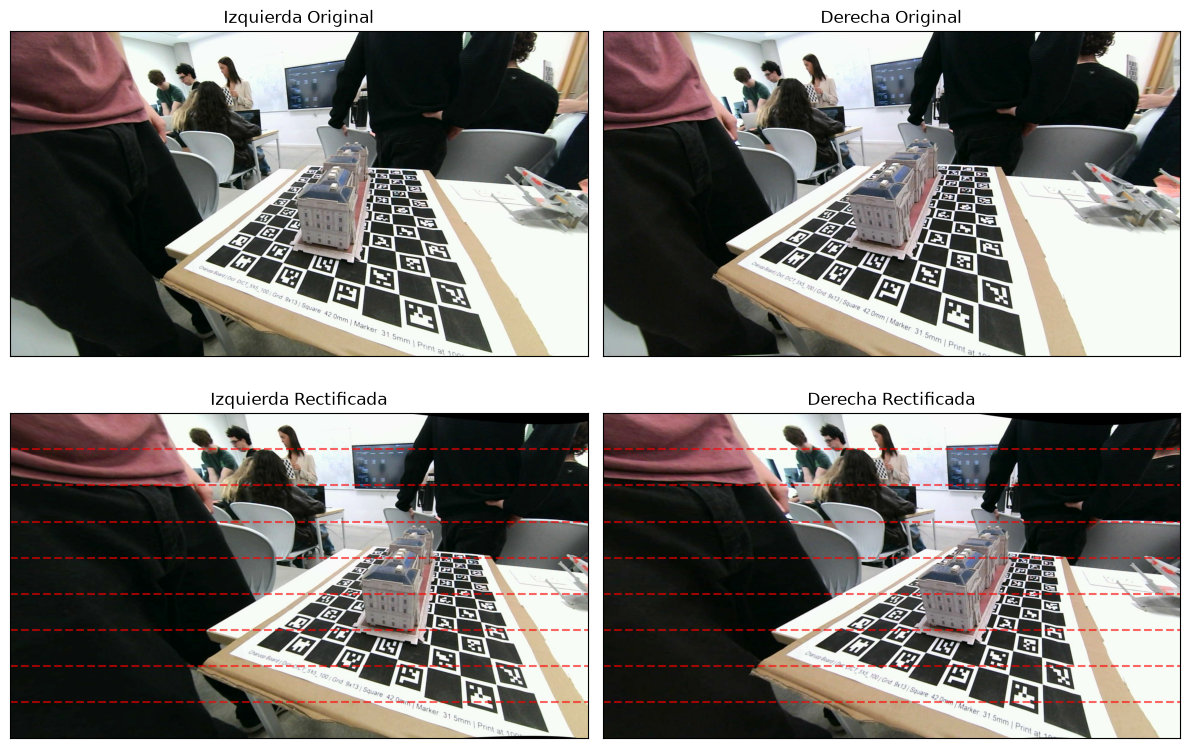

In [10]:
# --- Ejemplo de par original vs. rectificado (dataset propio) ---
# Calcular mapas de rectificación a partir de la calibración
R1, R2, P1, P2, Q, roi1, roi2 = cv.stereoRectify(K1, D1, K2, D2, image_size, R, t)

map1x, map1y = cv.initUndistortRectifyMap(K1, D1, R1, P1, image_size, cv.CV_32FC1)
map2x, map2y = cv.initUndistortRectifyMap(K2, D2, R2, P2, image_size, cv.CV_32FC1)

# Par de la MISMA cámara calibrada (dataset de reconstrucción)
PAR_EJEMPLO = "../data/raw/palacio"
img_left = cv.imread(f"{PAR_EJEMPLO}/left_0.jpg", cv.IMREAD_COLOR)
img_right = cv.imread(f"{PAR_EJEMPLO}/right_0.jpg", cv.IMREAD_COLOR)

rect_left = cv.remap(img_left, map1x, map1y, cv.INTER_LINEAR)
rect_right = cv.remap(img_right, map2x, map2y, cv.INTER_LINEAR)

# Visualización comparativa
fig, axs = plt.subplots(2, 2, figsize=(12, 8))
axs[0, 0].imshow(cv.cvtColor(img_left, cv.COLOR_BGR2RGB));   axs[0, 0].set_title("Izquierda Original")
axs[0, 1].imshow(cv.cvtColor(img_right, cv.COLOR_BGR2RGB));  axs[0, 1].set_title("Derecha Original")
axs[1, 0].imshow(cv.cvtColor(rect_left, cv.COLOR_BGR2RGB));  axs[1, 0].set_title("Izquierda Rectificada")
axs[1, 1].imshow(cv.cvtColor(rect_right, cv.COLOR_BGR2RGB)); axs[1, 1].set_title("Derecha Rectificada")

# Líneas epipolares horizontales de referencia sobre las rectificadas:
# un mismo punto físico debe caer en la misma fila en ambas imágenes.
for y in np.linspace(0, image_size[1], 10)[1:-1]:
    axs[1, 0].axhline(y, color='r', linestyle='--', alpha=0.6)
    axs[1, 1].axhline(y, color='r', linestyle='--', alpha=0.6)

for ax in axs.ravel():
    ax.set_xticks([]); ax.set_yticks([])

plt.tight_layout()

# Guardar figura para el informe
os.makedirs('../report/report_images', exist_ok=True)
fig.savefig('../report/report_images/rectificacion_palacio.png', dpi=120, bbox_inches='tight')
plt.show()